<a href="https://colab.research.google.com/github/devcodes28/AI-ML-Lab-24CSP503/blob/main/AI_ML_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Linear Regression**

**Dataset:** WHO Life Expectancy Data [https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who/data]

**Objective:** To perform end-to-end predictive modeling using Simple and
Multiple Linear Regression to identify and quantify the factors affecting life expectancy.



---



**Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Statsmodels for advanced assumption checking (VIF, QQ plots)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set plot style and random seed for reproducibility
sns.set_theme(style="whitegrid")
np.random.seed(42)

import warnings
warnings.filterwarnings('ignore')

**Load Dataset**

In [ ]:
df = pd.read_csv('Life Expectancy Data.csv')

# Clean column names (strip leading/trailing spaces)
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Last 5 Rows ---")
display(df.tail())

print("\n--- Dataset Information ---")
display(df.info())

print("\n--- Descriptive Statistics ---")
display(df.describe())

Dataset Shape: (2938, 22)

--- First 5 Rows ---


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5



--- Last 5 Rows ---


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.0,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.0,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.0,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.0,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8
2937,Zimbabwe,2000,Developing,46.0,665.0,24,1.68,0.0,79.0,1483,...,78.0,7.10,78.0,43.5,547.358878,12222251.0,11.0,11.2,0.434,9.8



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int6

None


--- Descriptive Statistics ---


,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


**Data Exploration** - Exploratory Data Analysis (EDA) helps us understand the underlying structure, detect anomalies, and uncover relationships between variables.

Target Variable: Life expectancy

We check for missing values, unique values, and visualize distributions.

--- Missing Values Count ---
Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

--- Duplicate Rows ---
Total duplicates: 0


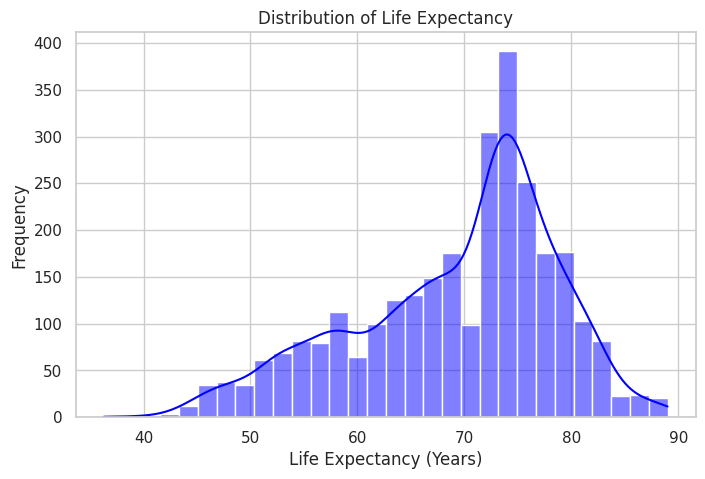

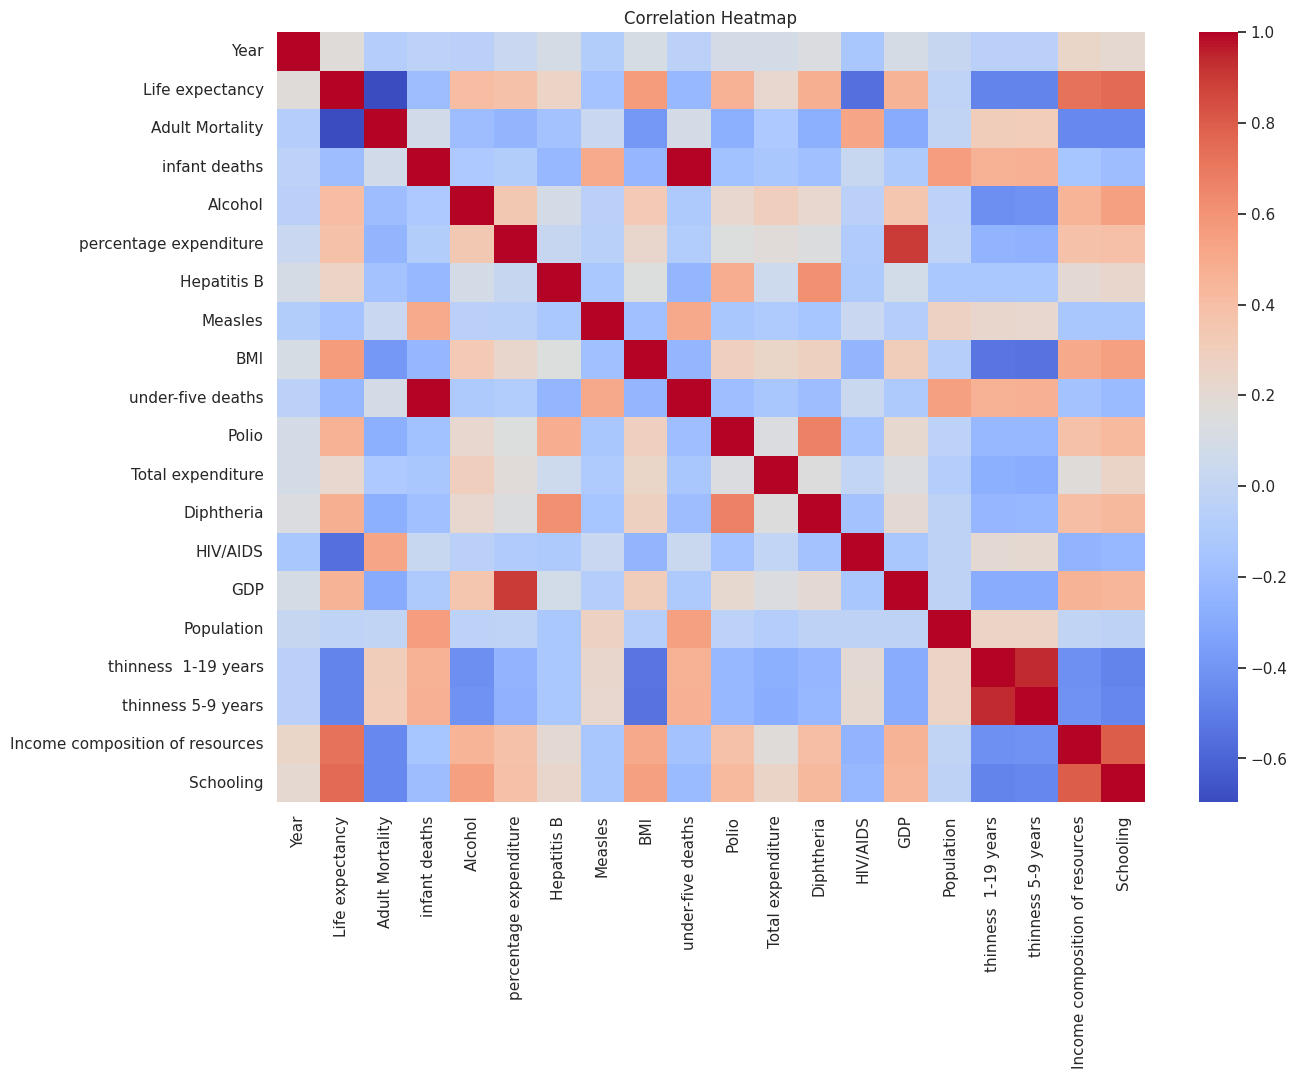

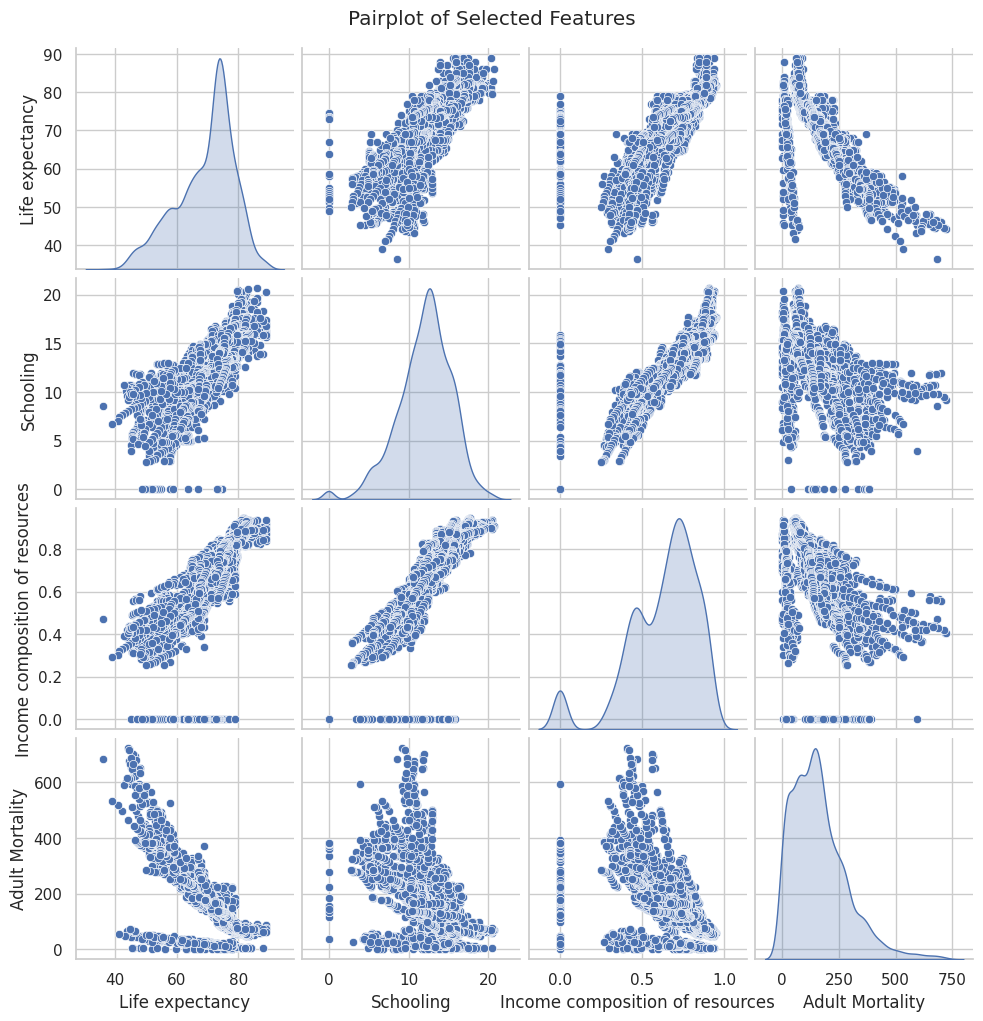

In [ ]:
print("--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print("Total duplicates:", df.duplicated().sum())

# Visualizing the Target Variable Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Life expectancy'], bins=30, kde=True, color='blue')
plt.title('Distribution of Life Expectancy')
plt.xlabel('Life Expectancy (Years)')
plt.ylabel('Frequency')
plt.show()

# Correlation Heatmap for numerical features
plt.figure(figsize=(14, 10))
# Select only numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), cmap='coolwarm', annot=False, fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# Pairplot for limited, highly correlated features
cols_to_plot = ['Life expectancy', 'Schooling', 'Income composition of resources', 'Adult Mortality']
sns.pairplot(df[cols_to_plot].dropna(), diag_kind='kde')
plt.suptitle('Pairplot of Selected Features', y=1.02)
plt.show()

**Observations:**

1. Missing Values: Several columns (like Hepatitis B, GDP, Population) contain significant missing data.

2. Target Distribution: Life expectancy is slightly left-skewed, peaking around 70-75 years.

3. Correlations: Schooling and Income composition of resources show a strong positive correlation with Life expectancy, making them excellent candidates for prediction. Adult Mortality shows a strong negative correlation.

**Data Preprocessing**

In [ ]:
# 1. Handle Missing Values (Impute with Median for numerical, Mode for categorical)
for col in df.columns:
    if df[col].dtype in ['float64', 'int64']:
        df[col].fillna(df[col].median(), inplace=True)
    else:
        df[col].fillna(df[col].mode()[0], inplace=True)

# 2. Handle Duplicates
df.drop_duplicates(inplace=True)

# 3. Categorical Encoding
# Label Encoding 'Status' (0 = Developed, 1 = Developing)
le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status'])

# We will drop 'Country' and 'Year' as they are identifiers/temporal, not direct physiological/economic predictors.
df_processed = df.drop(columns=['Country', 'Year'])

# Define Features and Target
X_full = df_processed.drop(columns=['Life expectancy'])
y_full = df_processed['Life expectancy']

# 4. Feature Scaling (Fit on the entire set for convenience in this lab setup, though fitting on train only is best practice)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_full), columns=X_full.columns)

# **Simple Linear Regression**

Based on our correlation matrix, Schooling has one of the highest positive correlations with Life Expectancy.Equation:$$y = \beta_0 + \beta_1 x$$(Life Expectancy = Intercept + Coefficient $\times$ Schooling)

In [ ]:
# Select single predictor
X_simple = X_scaled[['Schooling']]
y = y_full

# Train-Test Split (80% training, 20% testing)
X_train_s, X_test_s, y_train, y_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

# Initialize and Train Model
slr_model = LinearRegression()
slr_model.fit(X_train_s, y_train)

# Predict
y_pred_s = slr_model.predict(X_test_s)

# Print parameters
print(f"Intercept (b0): {slr_model.intercept_:.4f}")
print(f"Coefficient (b1): {slr_model.coef_[0]:.4f}")
print(f"Equation: Life Expectancy = {slr_model.intercept_:.2f} + ({slr_model.coef_[0]:.2f} * Standardized_Schooling)")

Intercept (b0): 69.2177
Coefficient (b1): 6.7841
Equation: Life Expectancy = 69.22 + (6.78 * Standardized_Schooling)


**Visualizations for Simple Linear Regression**

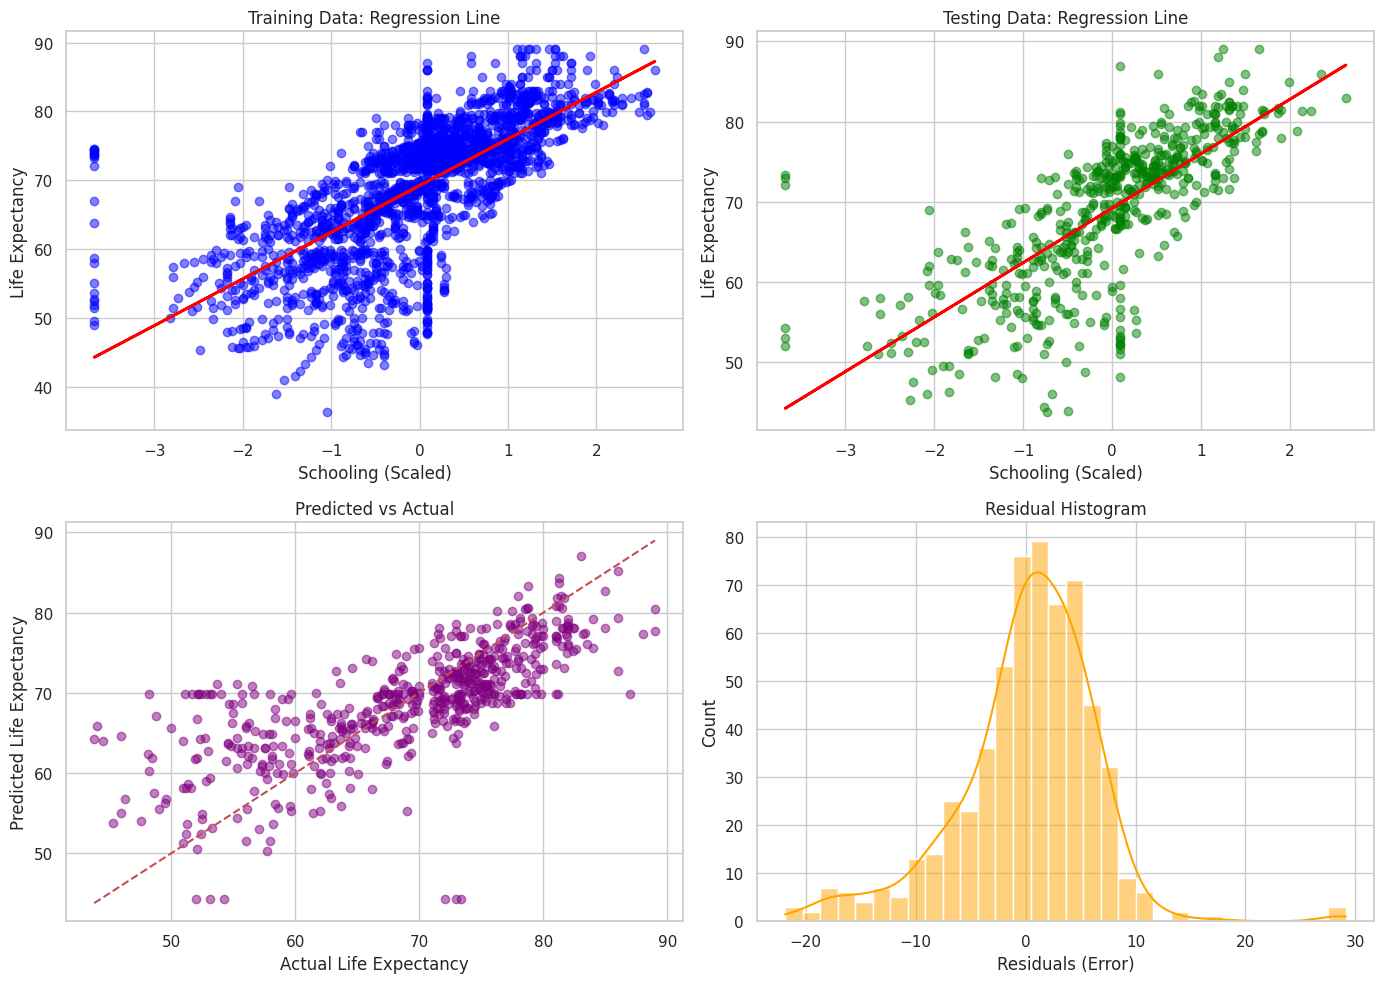

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Training Data Scatter & Line
axes[0, 0].scatter(X_train_s, y_train, alpha=0.5, color='blue')
axes[0, 0].plot(X_train_s, slr_model.predict(X_train_s), color='red', linewidth=2)
axes[0, 0].set_title('Training Data: Regression Line')
axes[0, 0].set_xlabel('Schooling (Scaled)')
axes[0, 0].set_ylabel('Life Expectancy')

# 2. Testing Data Scatter & Line
axes[0, 1].scatter(X_test_s, y_test, alpha=0.5, color='green')
axes[0, 1].plot(X_test_s, y_pred_s, color='red', linewidth=2)
axes[0, 1].set_title('Testing Data: Regression Line')
axes[0, 1].set_xlabel('Schooling (Scaled)')
axes[0, 1].set_ylabel('Life Expectancy')

# 3. Predicted vs Actual
axes[1, 0].scatter(y_test, y_pred_s, alpha=0.5, color='purple')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1, 0].set_title('Predicted vs Actual')
axes[1, 0].set_xlabel('Actual Life Expectancy')
axes[1, 0].set_ylabel('Predicted Life Expectancy')

# 4. Residual Histogram
residuals_s = y_test - y_pred_s
sns.histplot(residuals_s, kde=True, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Residual Histogram')
axes[1, 1].set_xlabel('Residuals (Error)')

plt.tight_layout()
plt.show()

Evaluation Metrics (Simple Regression)

1. MAE (Mean Absolute Error): Average absolute difference between predictions and actuals.
2. MSE (Mean Squared Error): Penalizes larger errors by squaring them.
3. RMSE (Root MSE): Error measured in the same units as the target (Years).
4. $R^2$ Score: Proportion of variance in the target explained by the model (closer to 1.0 is better).

In [ ]:
mae_s = mean_absolute_error(y_test, y_pred_s)
mse_s = mean_squared_error(y_test, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test, y_pred_s)

print("--- Simple Linear Regression Metrics ---")
print(f"MAE:  {mae_s:.4f}")
print(f"MSE:  {mse_s:.4f}")
print(f"RMSE: {rmse_s:.4f}")
print(f"R²:   {r2_s:.4f}")

--- Simple Linear Regression Metrics ---
MAE:  4.5928
MSE:  39.7696
RMSE: 6.3063
R²:   0.5411


# Multiple Linear Regression

Life expectancy depends on multiple factors. Multiple Linear Regression model using several meaningful predictors selected based on domain knowledge and correlation.

Equation:$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_n x_n$$

In [ ]:
# Select multiple features
features = ['Schooling', 'Income composition of resources', 'Adult Mortality', 'GDP', 'HIV/AIDS', 'BMI']
X_multi = X_scaled[features]

# Train-Test Split
X_train_m, X_test_m, y_train, y_test = train_test_split(X_multi, y, test_size=0.2, random_state=42)

# Train Model
mlr_model = LinearRegression()
mlr_model.fit(X_train_m, y_train)
y_pred_m = mlr_model.predict(X_test_m)

# Coefficients Table
coeff_df = pd.DataFrame(mlr_model.coef_, X_multi.columns, columns=['Coefficient'])
print(f"Intercept: {mlr_model.intercept_:.4f}\n")
display(coeff_df)

Intercept: 69.2641



,Coefficient
Schooling,2.743737
Income composition of resources,1.697457
Adult Mortality,-2.806092
GDP,0.710872
HIV/AIDS,-2.372886
BMI,1.246184


**Multiple Regression Visualizations**

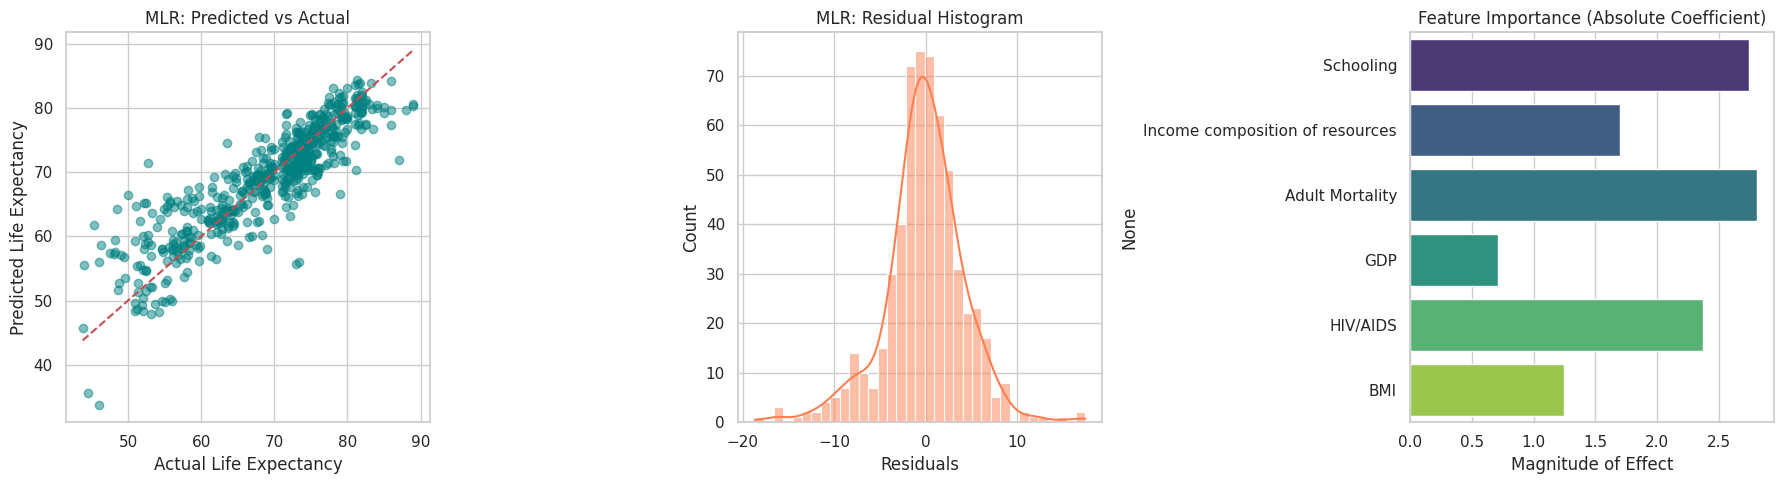

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Predicted vs Actual
axes[0].scatter(y_test, y_pred_m, alpha=0.5, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title('MLR: Predicted vs Actual')
axes[0].set_xlabel('Actual Life Expectancy')
axes[0].set_ylabel('Predicted Life Expectancy')

# 2. Residual Histogram
residuals_m = y_test - y_pred_m
sns.histplot(residuals_m, kde=True, ax=axes[1], color='coral')
axes[1].set_title('MLR: Residual Histogram')
axes[1].set_xlabel('Residuals')

# 3. Feature Importance (Absolute Coefficients)
importance = np.abs(mlr_model.coef_)
sns.barplot(x=importance, y=X_multi.columns, ax=axes[2], palette='viridis')
axes[2].set_title('Feature Importance (Absolute Coefficient)')
axes[2].set_xlabel('Magnitude of Effect')

plt.tight_layout()
plt.show()

**Model Validation**

In [ ]:
mae_m = mean_absolute_error(y_test, y_pred_m)
mse_m = mean_squared_error(y_test, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test, y_pred_m)

print("--- Multiple Linear Regression Metrics ---")
print(f"MAE:  {mae_m:.4f}")
print(f"MSE:  {mse_m:.4f}")
print(f"RMSE: {rmse_m:.4f}")
print(f"R²:   {r2_m:.4f}")

--- Multiple Linear Regression Metrics ---
MAE:  3.1431
MSE:  19.0735
RMSE: 4.3673
R²:   0.7799


Observation: The MLR model usually outperforms the SLR model (lower RMSE, higher $R^2$) because life expectancy is a complex phenomenon driven by multiple socioeconomic and health factors, rather than just schooling alone

**Cross Validation**

To ensure our model isn't just performing well on a specific 80-20 split, we use $k$-fold Cross Validation ($k=5$). This trains and tests the model 5 separate times on different data subsets.

In [ ]:
# Perform 5-fold cross validation on the MLR model using the full dataset (selected features)
cv_scores = cross_val_score(LinearRegression(), X_multi, y, cv=5, scoring='r2')

print("5-Fold CV R² Scores:", np.round(cv_scores, 4))
print(f"Mean R²: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

5-Fold CV R² Scores: [0.7678 0.7765 0.7893 0.7509 0.7477]
Mean R²: 0.7664
Standard Deviation: 0.0156


**Prediction**

In [ ]:
# Create new custom samples matching the selected features
# Features: 'Schooling', 'Income composition of resources', 'Adult Mortality', 'GDP', 'HIV/AIDS', 'BMI'
new_data = pd.DataFrame({
    'Schooling': [15.0, 5.0],
    'Income composition of resources': [0.85, 0.30],
    'Adult Mortality': [70, 300],
    'GDP': [50000, 1000],
    'HIV/AIDS': [0.1, 5.0],
    'BMI': [55.0, 20.0]
})

print("--- Custom Input Data ---")
display(new_data)

# We must scale the new data exactly how we scaled the training data
# Since we fit the scaler on ALL features originally, we need to create a dummy dataframe
# to apply the scaler, or extract the mean/scale specifically for these features.
# For simplicity, we re-fit a scaler specifically for these 6 features on the original data.

scaler_multi = StandardScaler()
X_multi_original = df_processed[features] # Unscaled original values
scaler_multi.fit(X_multi_original)

new_data_scaled = scaler_multi.transform(new_data)

# Predict
custom_predictions = mlr_model.predict(new_data_scaled)

print("\n--- Predictions ---")
for i, pred in enumerate(custom_predictions):
    print(f"Sample {i+1} Predicted Life Expectancy: {pred:.2f} years")

--- Custom Input Data ---


,Schooling,Income composition of resources,Adult Mortality,GDP,HIV/AIDS,BMI
0,15.0,0.85,70,50000,0.1,55.0
1,5.0,0.30,300,1000,5.0,20.0



--- Predictions ---
Sample 1 Predicted Life Expectancy: 79.86 years
Sample 2 Predicted Life Expectancy: 54.61 years


**Comparison Table**

In [ ]:
comparison_df = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Simple LR (1 feature)': [mae_s, mse_s, rmse_s, r2_s],
    'Multiple LR (6 features)': [mae_m, mse_m, rmse_m, r2_m]
})

print("--- Model Performance Comparison ---")
display(comparison_df)

--- Model Performance Comparison ---


,Metric,Simple LR (1 feature),Multiple LR (6 features)
0,MAE,4.592776,3.143106
1,MSE,39.769638,19.073498
2,RMSE,6.306317,4.367322
3,R²,0.541123,0.779923
